# Exp 3 — Two-Phase Training (Freeze → Unfreeze) — Improved v2

**Changes from original:**
1. Increased Phase 1 epochs (5 → 12) so head converges properly
2. Raised learning rates (were too conservative)
3. Added **sqrt-inverse-frequency** class weights to FocalLoss (gentle rebalance)
4. Added linear warmup scheduler for Phase 2
5. Increased Phase 2 epochs (15 → 25) with early stopping safety net


In [3]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path().resolve()))  # so 'from utils import *' works
from utils import *
print("utils loaded ✓")

utils loaded ✓


In [4]:
EXP_DIR   = ROOT / 'outputs' / 'swinv2_small_exp3'
CKPT_DIR_E = EXP_DIR / 'checkpoints'
FIG_DIR_E  = EXP_DIR / 'figures'
for d in (CKPT_DIR_E, FIG_DIR_E): d.mkdir(parents=True, exist_ok=True)
CKPT_P1   = CKPT_DIR_E / 'exp3_phase1_best.pt'
CKPT_PATH = CKPT_DIR_E / 'exp3_best.pt'

# ── Tuned hyperparameters ──────────────────────────────────────────────────────
PHASE1_EPOCHS = 12          # Was 5  → give head time to converge
PHASE2_EPOCHS = 25          # Was 15 → more room with warmup + early stopping

PHASE1_HEAD_LR = 1e-4       # Was 1e-4 → faster head convergence in Phase 1
PHASE2_HEAD_LR = 1e-5       # Was 1e-5 → was far too low
PHASE2_BACK_LR = 1e-6       # Was 1e-6 → 0.1× ratio to head LR
GRAD_CLIP      = 1.0

In [5]:
train_ds    = DRDataset(train_df, TRAIN_DIR, transform=enhanced_train_transform)
val_ds      = DRDataset(val_df,   VAL_DIR,   transform=val_transform)
test_ds     = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)
t_loader    = make_loader(train_ds, sampler=wrs_sampler)
v_loader    = make_val_loader(val_ds)
test_loader = make_val_loader(test_ds)

In [6]:
# ── Gently rebalanced Focal Loss ───────────────────────────────────────────────
# sqrt-inverse-frequency: boosts minority classes without crushing majority
# Max/min ratio is ~6× (vs 37× with raw inverse freq which killed No DR)
import numpy as np

class_counts = train_df['level'].value_counts().sort_index().values.astype(float)
sqrt_inv     = 1.0 / np.sqrt(class_counts)
alpha_weights = sqrt_inv / sqrt_inv.sum()
alpha_tensor  = torch.tensor(alpha_weights, dtype=torch.float32).to(device)

print("Class distribution:", class_counts.astype(int))
print("Alpha weights:     ", np.round(alpha_weights, 4))
print(f"Max/min ratio:      {alpha_weights.max()/alpha_weights.min():.1f}×")

Class distribution: [18067  1710  3704   611   496]
Alpha weights:      [0.0558 0.1813 0.1232 0.3032 0.3366]
Max/min ratio:      6.0×


In [7]:
# ── Phase 1: freeze backbone, train head only ─────────────────────────────────
set_seed()
model     = build_swin_model(pretrained=True).to(device)
criterion = FocalLoss(alpha= None, gamma=2.0) # changed 'alpha_tensor'
scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

for name, param in model.named_parameters():
    param.requires_grad = ('custom_head' in name)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable:,} trainable params (custom_head only)')

optimizer  = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_HEAD_LR, weight_decay=WEIGHT_DECAY)
scheduler1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE1_EPOCHS)

history_p1, _ = train_loop(model, criterion, optimizer, scheduler1, scaler,
                             t_loader, v_loader, CKPT_P1, epochs=PHASE1_EPOCHS)
print('Phase 1 complete.')

Downloaded and loaded.
SwinV2-Small | 49.0M params
Phase 1: 5,381 trainable params (custom_head only)
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.8935   0.4483     0.7008   0.3300  ★


2            0.7894   0.5659     0.6762   0.3277


3            0.7564   0.5925     0.7216   0.3107


4            0.7412   0.5975     0.7058   0.3246


5            0.7357   0.6035     0.7034   0.3207


6            0.7271   0.6112     0.7010   0.3150


7            0.7274   0.6117     0.7561   0.3029
Early stopping at epoch 7.

Best val κ = 0.3300
Phase 1 complete.


In [8]:
# ── Phase 2: unfreeze all, layer-wise LR, warmup + cosine ──────────────────────
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR

for param in model.parameters():
    param.requires_grad = True
print(f'Phase 2: {sum(p.numel() for p in model.parameters()):,} trainable params (all)')

ckpt_p1 = torch.load(CKPT_P1, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch {ckpt_p1["epoch"]}, κ={ckpt_p1["val_kappa"]:.4f})')

bp = [p for n,p in model.named_parameters() if 'custom_head' not in n and p.requires_grad]
hp = [p for n,p in model.named_parameters() if 'custom_head'     in n and p.requires_grad]
optimizer  = torch.optim.AdamW(
    [{'params':bp,'lr':PHASE2_BACK_LR},{'params':hp,'lr':PHASE2_HEAD_LR}],
    weight_decay=WEIGHT_DECAY)

# Warmup for 3 epochs then cosine decay for the rest
WARMUP_EPOCHS = 3
warmup_sched  = LinearLR(optimizer, start_factor=0.1, total_iters=WARMUP_EPOCHS)
cosine_sched  = CosineAnnealingLR(optimizer, T_max=PHASE2_EPOCHS - WARMUP_EPOCHS)
scheduler2    = SequentialLR(optimizer, [warmup_sched, cosine_sched],
                             milestones=[WARMUP_EPOCHS])

history_p2, best_kappa = train_loop(model, criterion, optimizer, scheduler2, scaler,
                                     t_loader, v_loader, CKPT_PATH, epochs=PHASE2_EPOCHS)
print(f'Phase 2 complete. Best κ = {best_kappa:.4f}')

Phase 2: 48,964,799 trainable params (all)
Loaded Phase 1 best (epoch 1, κ=0.3300)
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.8081   0.5531     0.7174   0.3060  ★


2            0.7543   0.6005     0.6683   0.3500  ★


3            0.7041   0.6552     0.5913   0.4138  ★


4            0.6659   0.6887     0.5453   0.4666  ★


...

19           0.4859   0.7857     0.5130   0.5122


20           0.4860   0.7870     0.5101   0.5055


21           0.4823   0.7891     0.5268   0.4997


22           0.4793   0.7929     0.5034   0.5121


23           0.4768   0.7938     0.5352   0.4894
Early stopping at epoch 23.

Best val κ = 0.5168
Phase 2 complete. Best κ = 0.5168


Random init.
SwinV2-Small | 49.0M params
Loaded exp3_best.pt  (epoch 17, κ=0.5168)



Exp3 — Test Set:
               precision    recall  f1-score   support

        No DR      0.885     0.572     0.695      3872
         Mild      0.113     0.402     0.177       366
     Moderate      0.353     0.479     0.406       794
       Severe      0.347     0.588     0.436       131
Proliferative      0.439     0.708     0.542       106

     accuracy                          0.549      5269
    macro avg      0.427     0.550     0.451      5269
 weighted avg      0.729     0.549     0.606      5269

QWK: 0.5425


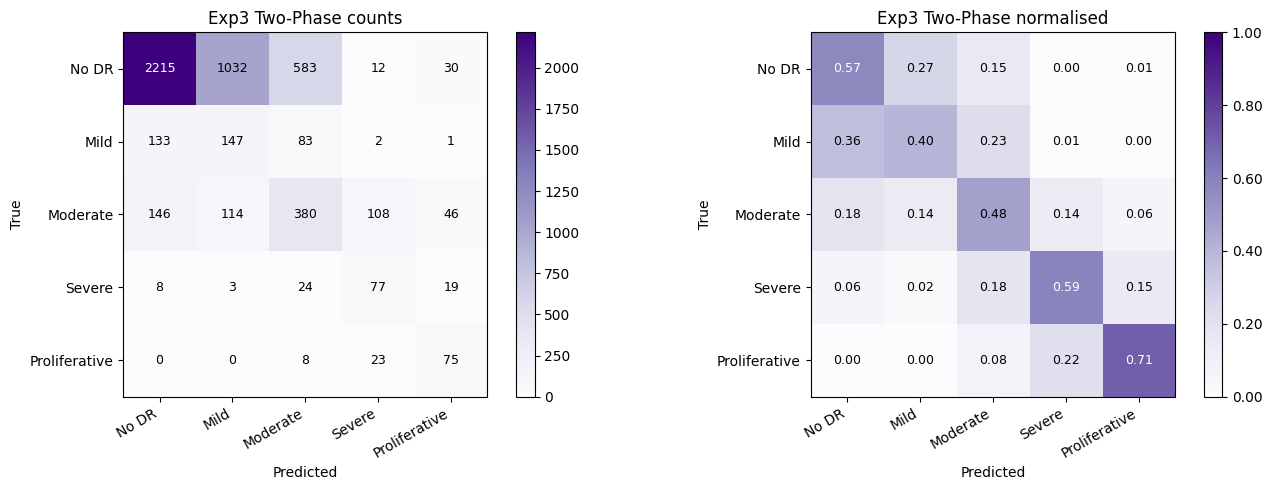

Exp3 QWK: 0.5425


In [9]:
y_true, y_pred = evaluate(model, criterion, optimizer, scaler,
                           test_loader, CKPT_PATH, 'Exp3')
plot_confusion(y_true, y_pred, 'Exp3 Two-Phase', FIG_DIR_E / 'exp3_confusion.png', cmap='Purples')

import json as _json
results = {'qwk': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
           'macro_f1': f1_score(y_true, y_pred, average='macro'),
           'f1_per': f1_score(y_true, y_pred, average=None).tolist(),
           'history_p1': history_p1, 'history_p2': history_p2}
with open(EXP_DIR / 'exp3_results.json', 'w') as f:
    _json.dump(results, f, indent=2)
print(f"Exp3 QWK: {results['qwk']:.4f}")